In [2]:
import numpy as np
import cirq
from matplotlib import pyplot as plt
from tqdm import tqdm

from nmrotoc.circuits.trotter import (
    make_product_formula_swap_network_dq_hamiltonian,
    first_order_trotterize_dq_hamiltonian,
    make_butterfly_circuit
)
from nmrotoc.dataclasses import (
    NMROTOCExperiment,
)
from nmrotoc.scripts.run_scripts import calculate_otoc_direct_all_times

# Simple Trotter implementation

This notebook goes through the calculation of first and second-order Trotterization using the helper functions in nmrotoc.circuits.trotter

In [3]:
# NMROTOCExperiment contains details of the experiment
# (e.g. Hamiltonian parameters, butterfly, measurement op)
experiment = NMROTOCExperiment.load("toluene_nmrotocexperiment.pkl")

Text(0, 0.5, 'OTOC target')

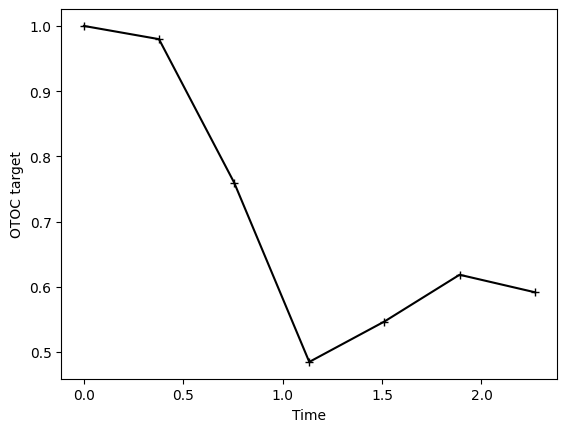

In [4]:
# Generate target OTOC for a set of times
times = np.arange(0, 7) * 0.378  # These are the times used in the experiment

# This function generates the 2^9 x 2^9 Hamiltonian,
# exponentiates it, and calculates the OTOC for you
otocs_target = calculate_otoc_direct_all_times(experiment, times)
plt.figure()
plt.plot(times, otocs_target, 'k+-')
plt.xlabel('Time')
plt.ylabel('OTOC target')

# Investigating Trotterized circuit

Due to locality restrictions, we often want to implement a Trotterized Hamiltonian evolution using a swap network; this permutes qubits by swaps alongside interactions, reducing the cost of implementation.

This makes understanding the circuit more difficult, so we have implemented a 'return_pairs' functionality to show the order of interactions in a product formula.

In [9]:
# Investigate the pairing order of a first-order Trotter formula passing through
# a swap network.

num_steps = 1
time = 0.4

# This function creates an object containing data about 'how to Trotterize' e.g.
# the order of couplings, what coupling strength to use for every timestep,
# whether to do first or second order, etc.
trotter_obj = first_order_trotterize_dq_hamiltonian(experiment, time, num_steps)

# Define a set of qubits to act on for cirq
qubits = [cirq.GridQubit(j, k) for j in range(3) for k in range(3)]

# This function consumes trotter_obj and a set of qubits to generate a circuit
circuit, qubit_id_refs, pairs = (
    make_product_formula_swap_network_dq_hamiltonian(
        trotter_obj, qubits, return_pairs=True
    )
)

assert len(pairs) == len(qubits) * (len(qubits) - 1) // 2
print('Implemented {} interactions'.format(len(pairs)))
print('Ordered list of interactions: ')
for pair in pairs:
    print(pair)

print(circuit)

Implemented 36 interactions
Ordered list of interactions: 
(0, 1)
(2, 3)
(4, 5)
(6, 7)
(0, 3)
(2, 5)
(4, 7)
(6, 8)
(1, 3)
(0, 5)
(2, 7)
(4, 8)
(1, 5)
(0, 7)
(2, 8)
(4, 6)
(3, 5)
(1, 7)
(0, 8)
(2, 6)
(3, 7)
(1, 8)
(0, 6)
(2, 4)
(5, 7)
(3, 8)
(1, 6)
(0, 4)
(5, 8)
(3, 6)
(1, 4)
(0, 2)
(7, 8)
(5, 6)
(3, 4)
(1, 2)
(0, 0): ───PhXZ(a=0.579,x=1,z=0)─────────FSim(0.5π, 0.317π)───────────────────────────────────────────────────────PhXZ(a=-1.25,x=1,z=0)─────────FSim(0.403π, -π)────────────────────────────────────────────────────────PhXZ(a=-1.25,x=1,z=0)─────────FSim(-0.065π, -π)───────────────────────────────────────────────────────PhXZ(a=-1.25,x=1,z=0)─────────FSim(0.338π, -π)─────────────────────────────────────────────────────────PhXZ(a=-1.25,x=1,z=0)─────────FSim(-0.756π, -π)─────────────────────────
                                         │                                                                                                      │                                                  

  0%|          | 0/6 [00:00<?, ?it/s]

100%|██████████| 6/6 [05:12<00:00, 52.00s/it]


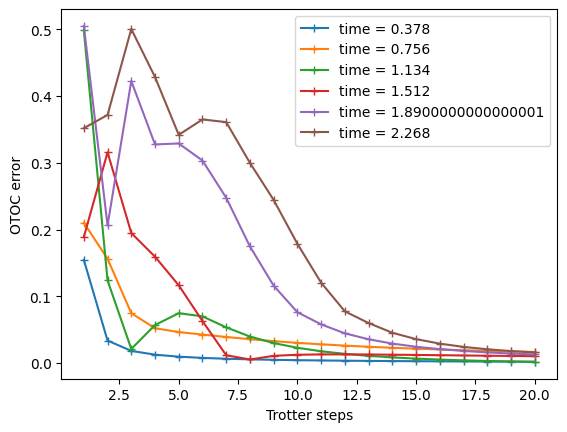

In [5]:
# Test convergence of first-order Trotterization

# Define a set of qubits to act on for cirq
qubits = [cirq.GridQubit(j, k) for j in range(3) for k in range(3)]

# Construct the measurement operator (same every circuit)
M_circuit = cirq.Circuit(experiment.msmt_gate(qubits[experiment.msmt_id]))
M = M_circuit.unitary(qubit_order=qubits)

# Store OTOC data
otocs = {}

# Define range of Trotter steps to test convergence over
num_steps_range = np.arange(1, 21)

plt.figure()
# Iterate over the previous time range (excluding t=0) and the range of Trotter steps
for tid, time in tqdm(list(enumerate(times[1:]))):
    otocs[time] = []
    for num_steps in num_steps_range:

        # This function creates an object containing data about 'how to Trotterize' e.g.
        # the order of couplings, what coupling strength to use for every timestep,
        # whether to do first or second order, etc.
        trotter_obj = first_order_trotterize_dq_hamiltonian(experiment, time, num_steps)

        # This function consumes trotter_obj and a set of qubits to generate a circuit
        circuit, qubit_id_refs = (
            make_product_formula_swap_network_dq_hamiltonian(trotter_obj, qubits)
        )

        # A swap network rearranges the assignment of spins to qubits, which is captured
        # by the 'qubit_id_refs' double-ended dictionary. This can be used alongside
        # the butterfly details contained in 'experiment' to make the circuit
        # corresponding to the butterfly
        butterfly = make_butterfly_circuit(experiment, qubit_id_refs)

        # For 9 qubits, it's faster to generate the unitaries and construct the OTOC
        # by hand.
        B = butterfly.unitary(qubit_order=qubits)
        unitary = circuit.unitary(qubit_order=qubits)
        otoc_matrix = (
            unitary.conj().T
            @ B
            @ unitary
            @ M
            @ unitary.conj().T
            @ B.conj().T
            @ unitary
            @ M
        )
        otoc = np.trace(otoc_matrix).real / (2 ** len(qubits))
        otocs[time].append(otoc)

    # Plot data so we have something to show
    plt.plot(
        num_steps_range,
        abs(otocs_target[tid + 1] - np.array(otocs[time])),
        "+-",
        label="time = {}".format(time),
    )
plt.xlabel('Trotter steps')
plt.ylabel('OTOC error')
plt.legend()

# Investigating trotter_obj

Trotterization in this workflow is divided up into two parts. First we define the unitaries that we will implement, then we define the order in which they occur. Options for the latter can be found in nmrotoc.dataclasses.py (look at ProductFormulaObj and subclasses), and functions to use / generate these can be found in nmrotoc.circuits.trotter.py Let's see here how to change the order of the swap network, and how to go from first to second-order Trotterization

In [6]:
# Test convergence of Trotterization with different orderings

time = times[6]
num_steps = 10
rng = np.random.RandomState(42)

otocs_first_order_test = []
otocs_second_order_test = []

for second_order in [False, True]:
    for _ in tqdm(np.arange(10)):

        # Make the trotter object
        trotter_obj = first_order_trotterize_dq_hamiltonian(experiment, time, num_steps)

        # We can change the order of iteration by changing trotter_obj.permutations.
        perm = rng.choice(9, size=9, replace=False)
        trotter_obj.permutations = [perm for _ in range(num_steps)]

        # We can change whether to do first or second-order Trotter by using the
        # 'alternate_order' flag
        trotter_obj.alternate_order = second_order

        # Consumes trotter_obj and a set of qubits to generate a circuit
        circuit, qubit_id_refs = (
            make_product_formula_swap_network_dq_hamiltonian(trotter_obj, qubits)
        )
        butterfly = make_butterfly_circuit(experiment, qubit_id_refs)

        # For 9 qubits, it's faster to generate the unitaries and construct the OTOC
        # by hand.
        B = butterfly.unitary(qubit_order=qubits)
        unitary = circuit.unitary(qubit_order=qubits)
        otoc_matrix = (
            unitary.conj().T
            @ B
            @ unitary
            @ M
            @ unitary.conj().T
            @ B.conj().T
            @ unitary
            @ M
        )
        otoc = np.trace(otoc_matrix).real / (2 ** len(qubits))
        if second_order is False:
            otocs_first_order_test.append(otoc)
        else:
            otocs_second_order_test.append(otoc)


Text(0, 0.5, 'OTOC est')

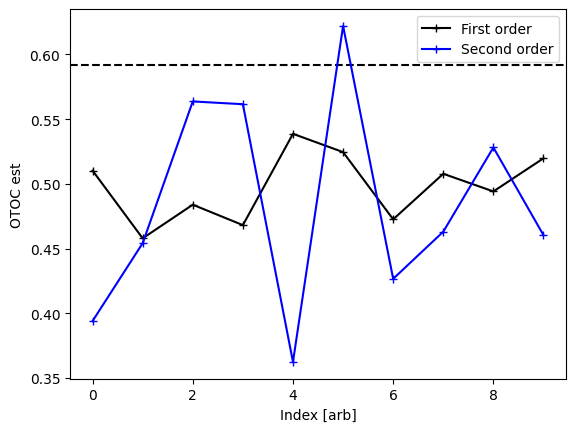

In [8]:
# Show something
plt.figure()
plt.axhline(otocs_target[6], color='k', linestyle='dashed')
plt.plot(otocs_first_order_test, 'k+-', label="First order")
plt.plot(otocs_second_order_test, 'b+-', label="Second order")
plt.legend()
plt.xlabel('Index [arb]')
plt.ylabel('OTOC est')